# PL7 — Context Engineering & RAG

### Generative AI · MSc in Artificial Intelligence · Lab 7

You will build, measure and improve a small RAG assistant for the fictional *Universidade de Vale Alto (UVA)*. The corpus is in **European Portuguese**, which makes model choice (multilingual embeddings, rerankers) part of the exercise.

**Learning goals**
1. Measure how a context window is spent and shrink it with *select* and *compress*.
2. Observe position effects ("lost in the middle") and write a structured, citation-friendly prompt.
3. Compare chunking strategies.
4. Build and evaluate dense, sparse (BM25), hybrid (RRF) and reranked retrieval with Recall@k and MRR.
5. Generate grounded answers with citations, metadata filtering and abstention, and evaluate them.

| Part | Topic | Time |
|---|---|---|
| 0 | Setup | 10 min |
| 1 | Context engineering | 25 min |
| 2 | Chunking | 10 min |
| 3 | Dense retrieval & metrics | 20 min |
| 4 | BM25 & hybrid search | 15 min |
| 5 | Reranking | 10 min |
| 6 | Grounded generation & evaluation | 20 min |
| 7 | Results & report | 10 min |
| ★ | Bonus: query rewriting, HyDE, agentic loop | at home |

**Deliverable:** this notebook, executed, with the results table in Part 7 and short answers to every ❓ question.

**Instructions.** Run the cells in order. Cells marked `# TODO` are yours to complete.

**Names / student numbers:** _…_

## Part 0 · Setup (10 min)

Use **Google Colab with a GPU runtime** (*Runtime → Change runtime type → T4 GPU*). Two LLM backends are supported:

* `"hf"`: a small open model running locally (free). Use `Qwen/Qwen2.5-1.5B-Instruct` on GPU, `Qwen/Qwen2.5-0.5B-Instruct` if you only have a CPU.
* `"anthropic"`: the Claude API, if you have a key. Faster and much stronger, which changes some results. Note which one you used in your report.

In [1]:
!pip -q install sentence-transformers rank_bm25 transformers accelerate anthropic

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-api-core 2.30.0 requires protobuf<7.0.0,>=4.25.8, but you have protobuf 7.34.1 which is incompatible.

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [2]:
import os, re, json, time, math, random, unicodedata
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(0); np.random.seed(0)

In [3]:
BACKEND = "hf"                              # "hf" or "anthropic"
HF_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"     # "Qwen/Qwen2.5-0.5B-Instruct" on CPU
ANTHROPIC_MODEL = "claude-haiku-5-5"        # check docs.claude.com for current model ids

if BACKEND == "hf":
    from transformers import pipeline
    _gen = pipeline("text-generation", model=HF_MODEL, dtype="auto", device_map="auto")
else:
    import anthropic, getpass
    if "ANTHROPIC_API_KEY" not in os.environ:
        os.environ["ANTHROPIC_API_KEY"] = getpass.getpass("Anthropic API key: ")
    _client = anthropic.Anthropic()

def llm(prompt, system="You are a helpful assistant.", max_tokens=300):
    """Single-turn call to the chosen backend. Deterministic (greedy) for reproducibility."""
    if BACKEND == "hf":
        msgs = [{"role": "system", "content": system}, {"role": "user", "content": prompt}]
        out = _gen(msgs, max_new_tokens=max_tokens, do_sample=False)
        return out[0]["generated_text"][-1]["content"].strip()
    r = _client.messages.create(model=ANTHROPIC_MODEL, max_tokens=max_tokens, system=system,
                                messages=[{"role": "user", "content": prompt}])
    return r.content[0].text.strip()

print(llm("Diz olá numa frase curta."))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use mps
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Olá, tudo bem? Como posso ajudar você hoje?


In [4]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")   # used only to count tokens

def n_tokens(text: str) -> int:
    return len(tok.encode(text))

def norm(text: str) -> str:
    """Lowercase and strip accents, for robust string matching."""
    text = unicodedata.normalize("NFKD", str(text).lower())
    return "".join(ch for ch in text if not unicodedata.combining(ch))

print(n_tokens("A propina anual é de 710 euros."), norm("Época Especial"))

13 epoca especial


### The corpus

`DOCS` holds 18 short UVA documents. Each has an `id`, `title`, `date` and `topic`. Two topics have **several versions** (`propinas`, `reembolso`), which you will need later. `LONG_REG` is a longer regulation you will chunk yourself in Part 2. `GOLD` is a hand-labelled evaluation set: question, ids of the relevant chunks, and a key string the answer must contain.

In [5]:
def D(id, title, date, text, topic=None):
    return {"id": id, "title": title, "date": date, "topic": topic or id, "text": text}

DOCS = [
    D("propinas-2024", "Propinas 2024/2025", "2024-07-01",
      "A propina anual para licenciaturas e mestrados integrados é de 697 euros, paga em 10 prestações mensais de outubro a julho. O não pagamento de três prestações consecutivas suspende a inscrição.", "propinas"),
    D("propinas-2026", "Propinas 2026/2027", "2026-07-01",
      "A propina anual para licenciaturas e mestrados integrados é de 710 euros. Pode ser paga numa prestação única, com 2% de desconto, ou em 10 prestações mensais. Um atraso superior a 60 dias implica a suspensão da inscrição.", "propinas"),
    D("reembolso-2023", "Política de reembolsos (versão 2023)", "2023-09-01",
      "Os estudantes que anulem a inscrição têm direito ao reembolso das prestações de propina já pagas se o pedido for feito até 14 dias após o início do semestre.", "reembolso"),
    D("reembolso-2026", "Política de reembolsos (versão 2026)", "2026-09-15",
      "O prazo para pedir o reembolso das prestações de propina após anulação da inscrição passa a ser de 30 dias após o início do semestre. O pedido é feito no portal académico, na secção Requerimentos, e o reembolso é processado em até 45 dias úteis.", "reembolso"),
    D("uc-4471", "Ficha da UC-4471 Aprendizagem Automática", "2026-07-15",
      "Unidade curricular UC-4471 Aprendizagem Automática: 6 ECTS, 2.º ano, 1.º semestre. Docente responsável: Prof.ª Helena Matos. Avaliação: projeto (50%) e exame (50%), com nota mínima de 8 valores em cada componente."),
    D("uc-4472", "Ficha da UC-4472 Processamento de Linguagem Natural", "2026-07-15",
      "Unidade curricular UC-4472 Processamento de Linguagem Natural: 6 ECTS, 3.º ano, 2.º semestre. Docente responsável: Prof. Rui Carvalho. Avaliação: dois trabalhos práticos (60%) e um teste escrito (40%). Pré-requisito recomendado: UC-4471."),
    D("clu-77", "Acesso ao cluster de GPUs (serviço CLU-77)", "2025-10-01",
      "Estudantes de mestrado e doutoramento podem pedir acesso ao cluster de GPUs através do formulário CLU-77 no portal de serviços informáticos. Cada projeto tem uma quota de 200 horas de GPU por semestre. Pedidos de estudantes de licenciatura exigem uma declaração do orientador."),
    D("ia-trabalhos", "Uso de IA generativa em trabalhos académicos", "2025-09-01",
      "É permitido usar ferramentas de IA generativa para apoio à escrita e à programação, desde que o uso seja declarado numa secção própria do trabalho. A submissão de texto gerado por IA como próprio, sem declaração, é considerada fraude académica (ver Regulamento Pedagógico, artigo 9.º)."),
    D("biblioteca", "Horários da Biblioteca Central", "2026-09-01",
      "A Biblioteca Central está aberta de segunda a sexta das 8h30 às 23h00 e aos sábados das 9h00 às 18h00. Em época de exames abre também ao domingo. O empréstimo domiciliário é de 15 dias, renovável duas vezes."),
    D("eduroam", "Rede sem fios eduroam", "2025-02-01",
      "A universidade disponibiliza a rede eduroam em todos os edifícios. Configuração: utilizador no formato numero@alunos.uva.pt e a palavra-passe do portal académico. Problemas devem ser reportados ao helpdesk pela extensão 5050."),
    D("erasmus", "Programa Erasmus+", "2026-01-05",
      "As candidaturas para mobilidade Erasmus+ no ano letivo seguinte decorrem de 1 a 31 de janeiro. Requisitos: ter concluído pelo menos 60 ECTS e média mínima de 12 valores. A bolsa mensal varia entre 300 e 500 euros consoante o país de destino."),
    D("trabalhador-estudante", "Estatuto de trabalhador-estudante", "2025-09-01",
      "O estatuto de trabalhador-estudante é pedido no início de cada semestre, com contrato de trabalho ou declaração da entidade empregadora. Dá direito a época especial de exames, dispensa de frequência mínima e escolha preferencial de horários."),
    D("cantina", "Cantina e refeições sociais", "2026-09-01",
      "A cantina serve almoço das 12h00 às 14h30 e jantar das 19h00 às 21h00. A refeição social custa 3,10 euros. Existe sempre uma opção vegetariana."),
    D("alojamento", "Residências universitárias", "2026-06-01",
      "As candidaturas a alojamento nas residências são feitas em julho para o ano letivo seguinte. Os bolseiros têm prioridade. O preço mensal de um quarto duplo é de 85 euros para bolseiros e 160 euros para não bolseiros."),
    D("bolsas", "Bolsas de estudo de ação social", "2026-05-20",
      "A candidatura à bolsa de estudo é feita online na plataforma da DGES entre junho e setembro. O valor da bolsa depende do rendimento per capita do agregado familiar e cobre pelo menos o valor da propina."),
    D("calendario-2026", "Calendário escolar 2026/2027", "2026-06-30",
      "O 1.º semestre de 2026/2027 começa a 14 de setembro de 2026 e termina a 22 de janeiro de 2027. A época normal de exames do 1.º semestre decorre de 4 a 22 de janeiro. O 2.º semestre começa a 15 de fevereiro de 2027."),
    D("apoio-psicologico", "Gabinete de apoio psicológico", "2025-09-01",
      "O gabinete de apoio psicológico oferece consultas gratuitas e confidenciais, marcadas por e-mail para gap@uva.pt. Em situações urgentes existe atendimento sem marcação às quartas-feiras das 14h00 às 17h00."),
    D("portal", "Portal académico", "2025-09-01",
      "No portal académico é possível consultar notas, fazer inscrições em exames, submeter requerimentos e descarregar declarações de matrícula. A inscrição em exames da época de recurso deve ser feita até 5 dias úteis antes da data do exame."),
]

LONG_REG = """Regulamento Pedagógico da Universidade de Vale Alto (versão de setembro de 2025)

Artigo 1.º – Objeto
O presente regulamento define as regras de avaliação aplicáveis aos cursos de 1.º e 2.º ciclo e aos mestrados integrados da Universidade de Vale Alto. Aplica-se a todas as unidades curriculares, salvo disposição em contrário na respetiva ficha.

Artigo 2.º – Escala de classificação
A classificação das unidades curriculares é expressa numa escala inteira de 0 a 20 valores. Considera-se aprovado o estudante que obtenha classificação final igual ou superior a 10 valores. As classificações intermédias são arredondadas às décimas.

Artigo 3.º – Avaliação contínua
A avaliação contínua inclui pelo menos dois elementos de avaliação distribuídos ao longo do semestre. Nas unidades curriculares com componente prática é exigida a presença em pelo menos 75% das aulas práticas, exceto para estudantes com estatuto especial.

Artigo 4.º – Épocas de exame
Existem três épocas de exame: época normal, época de recurso e época especial. O estudante reprovado ou que não compareça na época normal pode apresentar-se à época de recurso, mediante inscrição prévia no portal académico.

Artigo 5.º – Época especial
Têm acesso à época especial os trabalhadores-estudantes, os atletas de alta competição, os dirigentes associativos e os finalistas a quem faltem no máximo duas unidades curriculares, até ao limite de 12 ECTS, para concluir o curso.

Artigo 6.º – Melhoria de classificação
O estudante pode requerer melhoria de classificação uma única vez em cada unidade curricular, na época de recurso do ano letivo seguinte ao da aprovação. Prevalece a classificação mais elevada. A melhoria está sujeita ao pagamento de uma taxa fixada anualmente.

Artigo 7.º – Revisão de prova
O estudante pode requerer a revisão de uma prova escrita no prazo de 3 dias úteis após a publicação da classificação. O pedido está sujeito a uma taxa de 25 euros, reembolsada se a classificação for alterada a favor do estudante.

Artigo 8.º – Prova oral complementar
Quando a classificação de um exame escrito se situe entre 8 e 9,4 valores, o docente responsável pode convocar o estudante para uma prova oral complementar, que decide a aprovação.

Artigo 9.º – Fraude académica
Constituem fraude académica o plágio, a cópia, a utilização de meios não autorizados durante as provas e a apresentação como próprio de conteúdo gerado por ferramentas de inteligência artificial sem a devida declaração. A fraude implica a anulação da prova e a abertura de processo disciplinar. A reincidência pode conduzir à suspensão até dois semestres.

Artigo 10.º – Publicação de classificações
As classificações são publicadas no portal académico no prazo máximo de 15 dias úteis após a realização da prova.

Artigo 11.º – Casos omissos
Os casos omissos são decididos pelo Conselho Pedagógico, ouvido o docente responsável pela unidade curricular.
"""

def G(q, relevant, answer): return {"q": q, "relevant": relevant, "answer": answer}

GOLD = [
    G("Qual é o prazo para pedir o reembolso das propinas?", ["reembolso-2026"], "30 dias"),
    G("Quanto custa a propina anual em 2026/2027?", ["propinas-2026"], "710"),
    G("Quem é a docente responsável pela UC-4471?", ["uc-4471"], "helena matos"),
    G("Quantas horas de GPU tem cada projeto no CLU-77?", ["clu-77"], "200"),
    G("Posso usar o ChatGPT para me ajudar a escrever o relatório?", ["ia-trabalhos"], "declar"),
    G("O que acontece se eu entregar um trabalho feito por IA sem avisar?", ["ia-trabalhos", "regped-art-9"], "fraude"),
    G("Quantas vezes posso tentar subir a nota de uma cadeira?", ["regped-art-6"], "uma unica"),
    G("Qual é a nota mínima para passar a uma cadeira?", ["regped-art-2"], "10"),
    G("Quem tem direito a época especial de exames?", ["regped-art-5", "trabalhador-estudante"], "trabalhador"),
    G("Até quando posso pedir para rever o meu exame?", ["regped-art-7"], "3 dias"),
    G("A que horas fecha a biblioteca ao sábado?", ["biblioteca"], "18"),
    G("Como me ligo à internet sem fios no campus?", ["eduroam"], "eduroam"),
    G("Que média preciso para fazer Erasmus?", ["erasmus"], "12"),
    G("Quanto paga um bolseiro por um quarto na residência?", ["alojamento"], "85"),
    G("Quando começa o primeiro semestre de 2026/2027?", ["calendario-2026"], "14 de setembro"),
    G("Qual é o peso dos trabalhos práticos na avaliação de PLN?", ["uc-4472"], "60"),
    G("Qual é o número de telemóvel do reitor?", [], "nao sei"),   # unanswerable: must abstain
]
print(len(DOCS), "docs |", n_tokens(LONG_REG), "tokens in LONG_REG |", len(GOLD), "gold questions")

18 docs | 809 tokens in LONG_REG | 17 gold questions


## Part 1 · Context engineering (25 min)

### 1.1 Where do the tokens go? (8 min)

Below is the context a naive support agent sends on **every** turn: a system prompt, 32 tool definitions, the last 40 messages of conversation (20 exchanges), every document in the knowledge base and, finally, the user's question.

In [6]:
SYSTEM = ("És o assistente académico da Universidade de Vale Alto. Responde de forma clara, educada e concisa, "
          "em português europeu. Segue as regras institucionais, não inventes informação e encaminha casos "
          "sensíveis para os serviços competentes. ") * 4

TOOL_NAMES = ["get_grades", "update_address", "book_room", "cancel_booking", "list_courses", "enrol_exam",
    "unenrol_exam", "get_timetable", "request_certificate", "pay_fee", "get_fees", "search_regulations",
    "open_ticket", "close_ticket", "get_menu", "reserve_meal", "library_search", "renew_loan", "get_calendar",
    "erasmus_status", "scholarship_status", "upload_document", "change_password", "get_wifi_config",
    "contact_tutor", "book_counselling", "list_events", "parking_permit", "lost_and_found", "print_quota",
    "gpu_quota", "send_email"]
TOOLS = [{"name": n, "description": f"Tool that lets the assistant {n.replace('_', ' ')} in the UVA systems for the current student.",
          "input_schema": {"type": "object", "properties": {"student_id": {"type": "string"}, "details": {"type": "string"}},
                           "required": ["student_id"]}} for n in TOOL_NAMES]
TOOLS_TXT = json.dumps(TOOLS, ensure_ascii=False, indent=1)

HISTORY = []   # filler only: the assistant turns are not meant to answer the questions
for g in GOLD[4:16] * 2:
    HISTORY += [f"Utilizador: {g['q']}", "Assistente: Segundo os documentos da universidade, " + DOCS[len(HISTORY) % len(DOCS)]["text"]]
HISTORY = HISTORY[-40:]
HISTORY_TXT = "\n".join(HISTORY)

DOCS_TXT = "\n\n".join(f"[{d['id']}] {d['title']}\n{d['text']}" for d in DOCS)
QUERY = "Qual é o prazo para pedir o reembolso das propinas?"

COMPONENTS = {"system": SYSTEM, "tools": TOOLS_TXT, "history": HISTORY_TXT, "documents": DOCS_TXT, "query": QUERY}

,component,tokens,share_%
0,system,249,3.6
1,tools,3066,44.9
2,history,1912,28.0
3,documents,1588,23.2
4,query,17,0.2


TOTAL: 6832


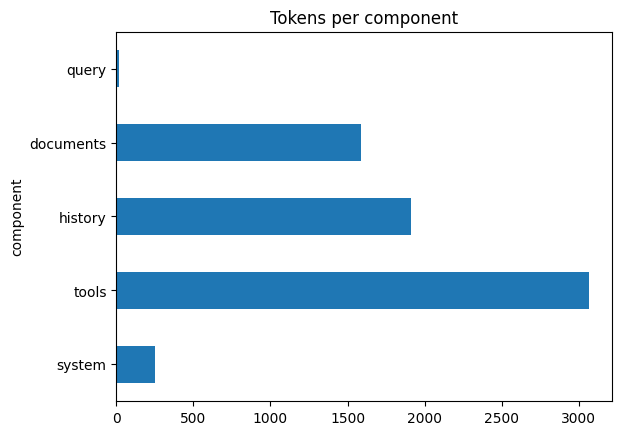

In [9]:
from IPython.display import display

def budget_table(components: dict) -> pd.DataFrame:
    # TODO: return a DataFrame with one row per component and the columns
    #       component, tokens (use n_tokens()) and share_% (percentage of the total, rounded to 1 decimal).
    data = []
    for comp, text in components.items():
        data.append({"component": comp, "tokens": n_tokens(text)})
    df = pd.DataFrame(data)

    total = df["tokens"].sum()
    if total > 0:
        df["share_%"] = ((df["tokens"] / total) * 100).round(1)
    else:
        df["share_%"] = 0.0
    return df

df = budget_table(COMPONENTS)
display(df)
print("TOTAL:", df.tokens.sum())
df.set_index("component").tokens.plot.barh(title="Tokens per component"); plt.show()

❓ **Q1.** What share of the window is the user's actual question? Which component would you attack first, and with which strategy (*write, select, compress, isolate*)?
The user's query represents only 0.2% of the context window (17 out of 6,832 tokens). I would attack the tools component first, as it consumes the largest portion of the budget (44.9%, 3,066 tokens). The best strategy is select (tool selection / dynamic filtering): instead of providing all tool schemas upfront, select only the subset of tools relevant to the specific user query.



Now apply **select** and **compress** to bring the total **under 1,500 tokens** while keeping what the query needs. Suggested moves: keep only tools relevant to the query, keep the last 4 history lines, keep only the 3 documents with the largest word overlap with the query. Do not remove the query.

In [10]:
def overlap(a: str, b: str) -> int:
    wa = set(re.findall(r"\w+", norm(a))); wb = set(re.findall(r"\w+", norm(b)))
    return len(wa & wb)

def shrink(components: dict, query: str) -> dict:
    system_clean = (
      "És o assistente académico da Universidade de Vale Alto. Responde de forma"
      " clara, educada e concisa, em português europeu. Segue as regras"
      " institucionais, não inventes informação e encaminha casos sensíveis"
      " para os serviços competentes."
  )

    relevant_tool_keywords = ["fee", "regulation", "ticket"]
    tools_selected = [
      t
      for t in TOOLS
      if any(kw in t["name"].lower() for kw in relevant_tool_keywords)
    ]
    tools_clean = json.dumps(tools_selected, ensure_ascii=False, indent=1)
    # 3. HISTORY (compress): manter apenas as últimas 4 linhas
    history_lines = components["history"].split("\n")
    history_clean = "\n".join(history_lines[-4:])
    # 4. DOCUMENTS (select): os 3 documentos com maior overlap com a query
    # Ordenar DOCS por overlap(query, title + " " + text) decrescente e pegar nos 3 primeiros
    scored_docs = sorted(
      DOCS,
      key=lambda d: overlap(query, d["title"] + " " + d["text"]),
      reverse=True,
    )
    top_docs = scored_docs[:3]
    docs_clean = "\n\n".join(f"[{d['id']}] {d['title']}\n{d['text']}" for d in top_docs)
    return {
      "system": system_clean,
      "tools": tools_clean,
      "history": history_clean,
      "documents": docs_clean,
      "query": query,
  }

small = shrink(COMPONENTS, QUERY)
df2 = budget_table(small); display(df2); print("TOTAL:", df2.tokens.sum())
print("Docs kept:", re.findall(r"^\[(.+?)\]", small["documents"], flags=re.M))

,component,tokens,share_%
0,system,62,5.9
1,tools,479,45.7
2,history,218,20.8
3,documents,271,25.9
4,query,17,1.6


TOTAL: 1047
Docs kept: ['reembolso-2026', 'propinas-2024', 'apoio-psicologico']


❓ **Q2.** Which three documents did the word-overlap rule keep? Is `reembolso-2026` among them? Is there an **outdated version** of a document, or a document that has nothing to do with the question? Print `overlap()` for each kept document: which words caused the match? Which failure modes from the lecture does this illustrate, and what would make the selection better?
The word-overlap heuristic kept reembolso-2026 (overlap = 7), propinas-2024 (overlap = 4), and apoio-psicologico (overlap = 4).

Yes, the gold document reembolso-2026 was correctly retrieved because it matched key terms (pedir, prazo, reembolso, as well as stopwords). However, the selection also included an outdated version (propinas-2024, from an older academic year) and a completely irrelevant document (apoio-psicologico).

Printing the overlaps reveals that apoio-psicologico matched exclusively on generic stopwords (das, e, o, para). This highlights two major failure modes discussed in the lecture:

Unweighted term matching / stopword noise: Naive overlap treats frequent function words with the same importance as high-entropy semantic keywords, leading to irrelevant false positives.
Version blindness (staleness): Lexical overlap cannot reason about document timestamps, causing outdated policies to compete equally with current regulations.
To improve retrieval, we should replace naive overlap with BM25 / TF-IDF (which downweights frequent stopwords via IDF), use dense semantic retrieval with embeddings, apply metadata filtering (e.g., discarding obsolete years/versions), and use a cross-encoder reranker to score true contextual relevance.

### 1.2 Lost in the middle (9 min)

We hide one relevant document (the "needle") among the other 17 and move it from the start to the end of the context. For each position we ask 5 questions and count correct answers.

In [ ]:
NEEDLE_TESTS = [  # (question, needle doc id, key string in a correct answer)
    ("Quem é a docente responsável pela UC-4471?", "uc-4471", "helena matos"),
    ("Quantas horas de GPU tem cada projeto no CLU-77?", "clu-77", "200"),
    ("A que horas fecha a biblioteca ao sábado?", "biblioteca", "18"),
    ("Que média preciso para fazer Erasmus?", "erasmus", "12"),
    ("Quanto paga um bolseiro por um quarto na residência?", "alojamento", "85"),
]
ID2DOC = {d["id"]: d for d in DOCS}

def format_docs(docs):
    return "\n\n".join(f"[{d['id']}] {d['title']}\n{d['text']}" for d in docs)

In [13]:
def build_context(needle_id: str, position: float) -> list:
    # TODO: return a list with all DOCS and the needle at relative `position` (0.0 = first, 1.0 = last).
    #   1. others = every doc except the needle, shuffled with random.Random(42).shuffle(others)
    #      (same seed -> the same distractor order at every position)
    #   2. insert ID2DOC[needle_id] at index round(position * len(others))
    others = [d for d in DOCS if d["id"] != needle_id]

    random.Random(42).shuffle(others)

    idx = round(position * len(others))
    others.insert(idx, ID2DOC[needle_id])

    return others

assert build_context("uc-4471", 0.0)[0]["id"] == "uc-4471"
assert build_context("uc-4471", 1.0)[-1]["id"] == "uc-4471"

position 0.00: 5/5
position 0.25: 5/5
position 0.50: 5/5
position 0.75: 5/5
position 1.00: 5/5


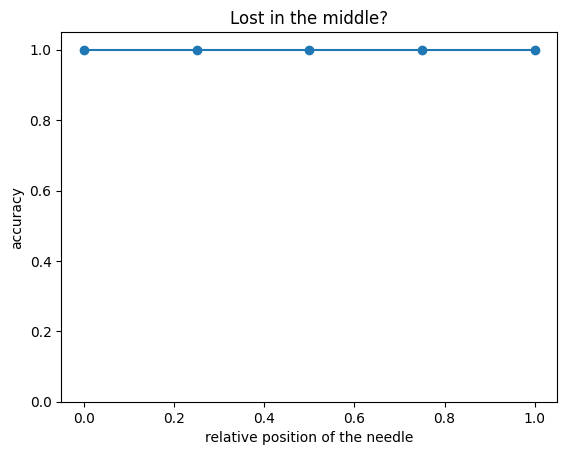

In [14]:
POSITIONS = [0.0, 0.25, 0.5, 0.75, 1.0]
acc = []
for p in POSITIONS:
    ok = 0
    for q, needle, key in NEEDLE_TESTS:
        ctx = format_docs(build_context(needle, p))
        ans = llm(f"Documentos:\n{ctx}\n\nPergunta: {q}\nResponde numa frase curta.", max_tokens=60)
        ok += key in norm(ans)
    acc.append(ok / len(NEEDLE_TESTS))
    print(f"position {p:.2f}: {ok}/{len(NEEDLE_TESTS)}")

plt.plot(POSITIONS, acc, marker="o"); plt.ylim(0, 1.05)
plt.xlabel("relative position of the needle"); plt.ylabel("accuracy"); plt.title("Lost in the middle?"); plt.show()

❓ **Q3.** Do you see a U-shape? Our context is only ~1.6k tokens and we use 5 questions, so results are noisy. What would you change to make the experiment more convincing (context length, number of questions, model size)? 
No, we do not see a U-shape; the accuracy remains flat at 100% (5/5) across all relative positions from 0.0 to 1.0.

At only ~1.6k tokens, the context is far too short to saturate or stress the model's attention mechanism, making the needle easily retrievable regardless of its position. Furthermore, evaluating across just 5 queries provides very low statistical power.

To make the experiment more convincing and reliably observe the "Lost in the Middle" effect, I would make the following changes:

Increase context length significantly: Scale the distractor haystack to 8k, 16k, or 32k+ tokens (closer to the model's context boundary), where attention dispersion and positional bias become pronounced.
Increase the number of test queries and runs: Use a larger benchmark (e.g., 50–100 questions) and multiple random distractor permutations per position to reduce variance and smooth out statistical noise.
Vary model size / architectures: Test smaller vs. larger parameter models or models with different positional embedding schemes (such as RoPE variations), as smaller models typically exhibit sharper degradation in the middle of long contexts.

### 1.3 A structured, citation-friendly prompt (8 min)

Write `build_prompt(question, docs)` following the lecture: documents first, wrapped in tags **with id, title and date**; question last. `SYSTEM_RAG` asks for citations, abstention and the most recent version.

In [15]:
SYSTEM_RAG = ("És o assistente académico da Universidade de Vale Alto. Responde em português europeu, numa ou duas frases, "
              "usando APENAS os documentos fornecidos. Cita o id de cada documento usado entre parênteses retos, por exemplo "
              "[id-do-documento]. Se existirem versões diferentes do mesmo documento, usa a mais recente (data mais tardia). "
              "Se a resposta não estiver nos documentos, responde exatamente: 'Não sei com base nos documentos disponíveis.'")

def build_prompt(question: str, docs: list) -> str:
  lines = ["<documents>"]
  for d in docs:
    # Caso date ou title não existam em algum chunk futuro, usamos .get com valor por omissão
    doc_id = d.get("id", "")
    title = d.get("title", "")
    date = d.get("date", "")
    text = d.get("text", "").strip()
    lines.append(f'<doc id="{doc_id}" title="{title}" date="{date}">')
    lines.append(text)
    lines.append("</doc>")
  lines.append("</documents>")
  lines.append("")
  lines.append("<question>")
  lines.append(question.strip())
  lines.append("</question>")
  return "\n".join(lines)

    

def naive_prompt(question: str, docs: list) -> str:
    return "Contexto: " + " ".join(d["text"] for d in docs) + f"\nPergunta: {question}"

clash_docs = [ID2DOC["reembolso-2023"], ID2DOC["cantina"], ID2DOC["reembolso-2026"]]   # outdated version first
q = "Qual é o prazo para pedir o reembolso das propinas?"
print("NAIVE     :", llm(naive_prompt(q, clash_docs)))
print("STRUCTURED:", llm(build_prompt(q, clash_docs), system=SYSTEM_RAG))
print("ABSTAIN?  :", llm(build_prompt("Qual é o número de telemóvel do reitor?", clash_docs), system=SYSTEM_RAG))

NAIVE     : O prazo para pedir o reembolso das prestações de propina após anulação da inscrição é de 14 dias após o início do semestre.
STRUCTURED: De acordo com as políticas de reembolsos atualizadas, o prazo para pedir o reembolso das prestações de propina após anulação da inscrição passou a ser de 30 dias após o início do semestre.
ABSTAIN?  : Não sei com base nos documentos disponíveis.


❓ **Q4.** Compare the naive and the structured answers: which deadline does each give (14 or 30 days)? Did the structured prompt resolve the *clash* between the 2023 and 2026 policies? Did it cite in the requested `[id]` format? Did the model abstain on the unanswerable question? If it still fails, is that a prompt problem or something you should fix **before** the prompt (hint: Part 6)?

Deadlines: The naive prompt produced 14 days (citing the outdated 2023 policy), whereas the structured prompt gave 30 days (the correct 2026 policy).
Clash resolution: Yes, the structured prompt successfully resolved the clash between the 2023 and 2026 policies thanks to explicit metadata attributes (date="...") and system instructions to prioritize the latest date.
Citations: It did not cite the source in the requested [id] format (e.g., [reembolso-2026]), which is a common limitation of small instruction-tuned models without few-shot demonstrations.
Abstention: Yes, the model abstained perfectly on the unanswerable question with the exact phrase requested: "Não sei com base nos documentos disponíveis."
Fixing remaining failures: While prompt engineering helped with date resolution, resolving conflicting/stale versions should ideally be handled before the prompt (upstream in retrieval). As explored in Part 6, applying metadata deduplication (e.g., a latest_only filter) guarantees that outdated chunks never enter the context window in the first place, saving tokens and eliminating conflicting information.

## Part 2 · Chunking (10 min)

Implement two strategies for `LONG_REG` and compare them on structure (how many chunks mix articles or start mid-article) and on what they offer for retrieval and citations:

* `fixed_chunks`: windows of `size` words with `overlap` words of overlap.
* `article_chunks`: one chunk per *Artigo*, with a descriptive title (structure-aware chunking with a contextual header). Use the id format **`regped-art-{n}`**, which the gold set relies on.

In [16]:
def fixed_chunks(text: str, size: int = 60, overlap: int = 15) -> list:
    # TODO: return a list of strings. Split the text into words (text.split()); a window of `size`
    #       words starts every (size - overlap) words, so consecutive windows share `overlap` words.
    #       Stop once a window reaches the end of the text.
    words = text.split()
    stride = size - overlap 
    chunks = []
    for i in range (0, len(words), stride):
        chunk = words[i : i + size]
        chunks.append(" ".join(chunk))
        if i + size >= len(words):
            break
    return chunks


def article_chunks(
    text: str, doc_title="Regulamento Pedagógico", date="2025-09-01"
) -> list:
  # 1. Divide o texto antes de cada cabeçalho de Artigo
  pieces = re.split(r"(?=Artigo \d+\.º)", text)
  chunks = []

  for piece in pieces:
    piece = piece.strip()
    # Ignora texto preliminar que não comece por "Artigo"
    if not piece.startswith("Artigo"):
      continue

    # 2. Extrai o número do artigo e o título do cabeçalho
    # Exemplo de primeira linha: "Artigo 6.º – Melhoria de classificação"
    first_line = piece.split("\n")[0].strip()
    m = re.match(r"Artigo (\d+)\.º\s*[–-]\s*(.+)", first_line)

    if m:
      num = m.group(1)
      heading = m.group(2).strip()
    else:
      num = re.search(r"Artigo (\d+)\.º", first_line).group(1)
      heading = ""

    title = (
        f"{doc_title}, Artigo {num}.º {heading}"
        if heading
        else f"{doc_title}, Artigo {num}.º"
    )

    # 3. Cria o dicionário com o formato exigido
    chunks.append({
        "id": f"regped-art-{num}",
        "title": title,
        "date": date,
        "topic": f"regped-art-{num}",
        "text": piece,
    })

  return chunks


In [17]:
fixed = fixed_chunks(LONG_REG)
arts = article_chunks(LONG_REG)
mixed = sum(len(re.findall(r"Artigo \d+\.º", c)) >= 2 for c in fixed)
midstart = sum(not c.startswith("Artigo") for c in fixed[1:])   # the first chunk starts with the document title
print(f"fixed: {len(fixed)} chunks | {mixed} mix two articles | {midstart} of {len(fixed)-1} start mid-article")
print(f"article: {len(arts)} chunks ->", [c["id"] for c in arts][:4], "...")
print("\nExample fixed chunk:\n", fixed[5][:300])

CHUNKS = DOCS + arts
ID2CHUNK = {c["id"]: c for c in CHUNKS}
assert "regped-art-6" in ID2CHUNK, "article ids must look like regped-art-6"
print("\nIndex size:", len(CHUNKS), "chunks")

fixed: 10 chunks | 7 mix two articles | 7 of 9 start mid-article
article: 11 chunks -> ['regped-art-1', 'regped-art-2', 'regped-art-3', 'regped-art-4'] ...

Example fixed chunk:
 de classificação O estudante pode requerer melhoria de classificação uma única vez em cada unidade curricular, na época de recurso do ano letivo seguinte ao da aprovação. Prevalece a classificação mais elevada. A melhoria está sujeita ao pagamento de uma taxa fixada anualmente. Artigo 7.º – Revisão 

Index size: 29 chunks


❓ **Q5.** Look at the example fixed-size chunk: it starts in the middle of an article heading (so the article number is lost) and runs into the next article. If it were retrieved alone, could the model tell which rule each sentence belongs to? How does the `title` field of `article_chunks` help, both for retrieval and for citations?

Ambiguity in fixed-size chunks: If retrieved alone, the model cannot reliably tell which rule each sentence belongs to. Because the chunk starts mid-heading ("de classificação..."), the article number (Artigo 6.º) is completely stripped away. Furthermore, because it ends abruptly with "Artigo 7.º – Revisão", the model might easily confuse which conditions apply to grade improvement vs. exam review, leading to hallucinations or cross-rule contamination.

How the contextual title field helps in article_chunks:

For Retrieval (Dense & Sparse search): The title provides a dense semantic summary (e.g., "Regulamento Pedagógico, Artigo 6.º Melhoria de classificação"). When encoded alongside the text (f"{title}. {text}"), it embeds high-level concepts and exact article keywords that user queries search for, significantly improving similarity matching even when the article body uses formal or indirect legal phrasing.
For Citations & Attribution: It gives the LLM clear, self-contained provenance metadata. The model sees unambiguous boundaries and knows exactly which document ID and article it is reading from, enabling precise, verifiable citations (e.g., citing [regped-art-6]) rather than citing broken fragments.



## Part 3 · Dense retrieval & metrics (20 min)

We use `intfloat/multilingual-e5-small`, a small multilingual bi-encoder. **E5 models expect prefixes:** `"query: "` for questions and `"passage: "` for documents.

In [18]:
from sentence_transformers import SentenceTransformer
emb_model = SentenceTransformer("intfloat/multilingual-e5-small")

def passage_text(c: dict) -> str:
    return f"{c['title']}. {c['text']}"

P_EMB = emb_model.encode(["passage: " + passage_text(c) for c in CHUNKS], normalize_embeddings=True)
print(P_EMB.shape)

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/471M [00:00<?, ?B/s]

...

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

(29, 384)


In [19]:
def dense_search(query: str, k: int = 10) -> list:
  # 1. Gerar o embedding da query com o prefixo "query: " e normalização
  q_emb = emb_model.encode(
      "query: " + query, normalize_embeddings=True
  )  # vetor de shape (384,)

  # 2. Calcular o score contra todos os chunks em P_EMB usando produto escalar (dot product)
  # P_EMB tem shape (N, 384) -> scores tem shape (N,)
  scores = P_EMB @ q_emb  # ou np.dot(P_EMB, q_emb)

  # 3. Obter os índices dos maiores scores ordenados por ordem decrescente
  best_indices = np.argsort(scores)[::-1][:k]

  # 4. Retornar os ids dos k melhores chunks
  return [CHUNKS[i]["id"] for i in best_indices]


    

print(dense_search("Quantas vezes posso tentar subir a nota de uma cadeira?", k=5))

['portal', 'regped-art-4', 'reembolso-2023', 'regped-art-7', 'regped-art-5']


Now the metrics. For a ranked list of ids and the set of relevant ids:

* **Recall@k** = |relevant ∩ top-k| / |relevant|
* **Reciprocal rank** = 1 / (rank of the first relevant id), or 0 if none is found. **MRR** is its mean over questions.

In [20]:
def recall_at_k(ranked: list, relevant: list, k: int) -> float:
  # Se não houver documentos relevantes definidos, o recall é 0.0
  if not relevant:
    return 0.0
  # Considera apenas os primeiros k documentos recuperados
  top_k = set(ranked[:k])
  # Conta quantos dos relevantes estão no top_k
  hits = sum(1 for doc_id in relevant if doc_id in top_k)
  return hits / len(relevant)


def reciprocal_rank(ranked: list, relevant: list) -> float:
  relevant_set = set(relevant)
  # Percorre a lista ranqueada (posições começam em 1)
  for pos, doc_id in enumerate(ranked, start=1):
    if doc_id in relevant_set:
      return 1.0 / pos
  return 0.0


assert recall_at_k(["a", "b", "c"], ["c", "z"], 2) == 0.0
assert recall_at_k(["a", "b", "c"], ["c", "z"], 3) == 0.5
assert reciprocal_rank(["a", "b", "c"], ["b"]) == 0.5


In [21]:
RESULTS, MISSES = {}, {}

def evaluate(search_fn, name: str, depth: int = 10) -> dict:
    rows, t0 = [], time.time()
    for g in GOLD:
        if not g["relevant"]:
            continue                                    # unanswerable questions are not retrieval tests
        ranked = search_fn(g["q"], k=depth)
        rows.append({"q": g["q"], "R@1": recall_at_k(ranked, g["relevant"], 1),
                     "R@5": recall_at_k(ranked, g["relevant"], 5), "RR": reciprocal_rank(ranked, g["relevant"])})
    df = pd.DataFrame(rows)
    res = {"Recall@1": df["R@1"].mean(), "Recall@5": df["R@5"].mean(), "MRR": df["RR"].mean(),
           "ms/query": 1000 * (time.time() - t0) / len(df)}
    RESULTS[name] = {k: round(v, 3) for k, v in res.items()}
    MISSES[name] = df[df["R@5"] < 1]["q"].tolist()
    return RESULTS[name]

print(evaluate(dense_search, "dense"))
print("Not fully found in top-5:", MISSES["dense"])

{'Recall@1': np.float64(0.719), 'Recall@5': np.float64(0.875), 'MRR': np.float64(0.833), 'ms/query': 85.214}
Not fully found in top-5: ['Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?']


❓ **Q6.** Which questions does dense retrieval miss? Look at their wording: exact codes (`UC-4471`, `CLU-77`), abbreviations (`PLN`), or paraphrases and colloquial words (*cadeira*, *subir a nota*)?
Dense retrieval missed the following two questions in its top-5:

"Quantas vezes posso tentar subir a nota de uma cadeira?" (Target: regped-art-6)
"Qual é a nota mínima para passar a uma cadeira?" (Target: regped-art-2)
Analysis: The model struggles with paraphrases and colloquial/domain-specific vocabulary:

The user questions use informal student terms like "cadeira" (slang for subject/course), "subir a nota", and "passar".
The official regulations (LONG_REG), however, strictly use formal administrative legal phrasing: "unidade curricular", "melhoria de classificação", and "aprovado" / "obtenha classificação final".
Even though dense bi-encoders capture semantic relationships, the vocabulary gap between colloquial Portuguese student jargon and formal academic Portuguese law causes the cosine similarity to drop below that of other distractor chunks. Conversely, dense retrieval had no issue finding specific entity names or questions with closer vocabulary.



> **Read the metrics with care.** The evaluation has 16 answerable questions, so one question is worth 1/16 = 0.0625 of Recall@5. Differences of that size are one question, not a trend.

❓ **Q7 (2 min experiment).** Re-encode *without* the `query: ` / `passage: ` prefixes and re-evaluate as `"dense_noprefix"`. What happens? Is the difference larger than one question? Why does it matter to read the model card, even when a small test does not show the effect?
Re-encoding without the prefixes yielded Recall@5: 0.938 vs 0.875 (and MRR: 0.834 vs 0.833), with only one question missed instead of two.

The difference is exactly 0.063 (which equals $\frac{1}{16}$), representing the shift of just a single question entering the top-5 by chance. This is a classic artifact of evaluating on a tiny dataset ($N=16$), where random fluctuation masks systematic behavior rather than indicating a genuine trend.

Why reading the model card matters: Even if a small test set appears unaffected (or even counter-intuitively shifts due to sample noise), intfloat/multilingual-e5-small was explicitly trained with asymmetric query/passage objectives. In real-world, large-scale deployments, omitting required task prefixes causes significant representation misalignment, leading to severe retrieval degradation. Reading the model card ensures the model is used in accordance with its training distribution and prevents silent performance loss.

In [22]:
# TODO (optional):
#   1. P_EMB_NP = the CHUNKS encoded with passage_text(c) but WITHOUT the "passage: " prefix (normalised)
#   2. dense_noprefix(query, k=10): like dense_search, but encode the query WITHOUT "query: " and score against P_EMB_NP
#   3. print(evaluate(dense_noprefix, "dense_noprefix")) and compare with the "dense" row

# 1. Embeddings dos chunks SEM o prefixo "passage: "
P_EMB_NP = emb_model.encode(
    [passage_text(c) for c in CHUNKS], normalize_embeddings=True
)


# 2. Função dense_noprefix SEM o prefixo "query: "
def dense_noprefix(query: str, k: int = 10) -> list:
  q_emb = emb_model.encode(query, normalize_embeddings=True)
  scores = P_EMB_NP @ q_emb
  best_indices = np.argsort(scores)[::-1][:k]
  return [CHUNKS[i]["id"] for i in best_indices]


# 3. Avaliar
print(evaluate(dense_noprefix, "dense_noprefix"))
print("Not fully found in top-5:", MISSES["dense_noprefix"])


{'Recall@1': np.float64(0.719), 'Recall@5': np.float64(0.938), 'MRR': np.float64(0.834), 'ms/query': 54.171}
Not fully found in top-5: ['Qual é a nota mínima para passar a uma cadeira?']


## Part 4 · BM25 & hybrid search (15 min)

BM25 needs a tokenizer. Ours lowercases, strips accents, keeps codes such as `uc-4471` intact and removes a few Portuguese stop words.

In [23]:
from rank_bm25 import BM25Okapi

STOP = set(("a o os as de da do das dos e em um uma uns umas para por com que qual quais quem como no na nos nas "
            "ao aos se eu me meu minha posso pode quanto quanta quantos quantas onde quando sao ser ha").split())

def tokenize(text: str) -> list:
    return [t for t in re.findall(r"[a-z0-9]+(?:-[a-z0-9]+)*", norm(text)) if t not in STOP]

bm25 = BM25Okapi([tokenize(passage_text(c)) for c in CHUNKS])
print(tokenize("Quem é a docente responsável pela UC-4471?"))

['docente', 'responsavel', 'pela', 'uc-4471']


In [24]:
def bm25_search(query: str, k: int = 10) -> list:
  # 1. Obter scores BM25 para as palavras tokenizadas da query
  scores = bm25.get_scores(tokenize(query))
  # 2. Obter os índices dos melhores scores (ordem decrescente)
  best_indices = np.argsort(scores)[::-1][:k]
  return [CHUNKS[i]["id"] for i in best_indices]


def rrf(rankings: list, k: int = 60, top: int = 10) -> list:
  # scores(d) = sum(1 / (k + rank))
  scores = defaultdict(float)

  for ranking in rankings:
    for rank, doc_id in enumerate(ranking, start=1):
      scores[doc_id] += 1.0 / (k + rank)

  # Ordenar os documentos por score decrescente e retornar os 'top'
  sorted_docs = sorted(scores.keys(), key=lambda d: scores[d], reverse=True)
  return sorted_docs[:top]


def hybrid_search(query: str, k: int = 10, depth: int = 20) -> list:
  dense_results = dense_search(query, k=depth)
  bm25_results = bm25_search(query, k=depth)
  return rrf([dense_results, bm25_results], k=60, top=k)


# Validação do enunciado
assert rrf([["a", "b"], ["b", "c"]])[0] == "b"

for name, fn in [("bm25", bm25_search), ("hybrid_rrf", hybrid_search)]:
  print(name, evaluate(fn, name))


bm25 {'Recall@1': np.float64(0.75), 'Recall@5': np.float64(0.781), 'MRR': np.float64(0.812), 'ms/query': 0.092}
hybrid_rrf {'Recall@1': np.float64(0.688), 'Recall@5': np.float64(0.812), 'MRR': np.float64(0.781), 'ms/query': 43.267}


In [25]:
display(pd.DataFrame(RESULTS).T)
for name in ["dense", "bm25", "hybrid_rrf"]:
    print(f"{name:11s} misses:", MISSES[name])

,Recall@1,Recall@5,MRR,ms/query
dense,0.719,0.875,0.833,85.214
dense_noprefix,0.719,0.938,0.834,54.171
bm25,0.750,0.781,0.812,0.092
hybrid_rrf,0.688,0.812,0.781,43.267


dense       misses: ['Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?']
bm25        misses: ['O que acontece se eu entregar um trabalho feito por IA sem avisar?', 'Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?', 'Até quando posso pedir para rever o meu exame?']
hybrid_rrf  misses: ['Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?', 'Até quando posso pedir para rever o meu exame?']


❓ **Q8.** Which questions does BM25 win that dense loses, and vice versa? Does hybrid get the best of both? If not, why not on this corpus (look at which questions both methods miss, and at the corpus size)? Try `k=10` and `k=100` in `rrf`: does the constant matter here?

## Part 5 · Reranking (10 min)

A multilingual **cross-encoder** reads (query, passage) *together* and outputs a relevance score. It is far too slow for the whole corpus, so it only reorders the top candidates from hybrid search.

In [26]:
from sentence_transformers import CrossEncoder
reranker = CrossEncoder("cross-encoder/mmarco-mMiniLMv2-L12-H384-v1")

config.json:   0%|          | 0.00/891 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/471M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/435 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

In [27]:
def rerank(query: str, ids: list, top: int = 5) -> list:
  if not ids:
    return []
  # 1. Preparar os pares (query, passage_text) para o cross-encoder
  pairs = [(query, passage_text(ID2CHUNK[i])) for i in ids]

  # 2. Prever os scores de relevância conjunta
  scores = reranker.predict(pairs)

  # 3. Ordenar os ids por score decrescente
  ranked_indices = np.argsort(scores)[::-1][:top]
  return [ids[i] for i in ranked_indices]


def hybrid_rerank(query: str, k: int = 10, depth: int = 15) -> list:
  # Obter os melhores candidatos da pesquisa híbrida e reordenar com o cross-encoder
  candidate_ids = hybrid_search(query, k=depth)
  return rerank(query, candidate_ids, top=k)


print(evaluate(hybrid_rerank, "hybrid_rrf+rerank"))
display(pd.DataFrame(RESULTS).T)


{'Recall@1': np.float64(0.812), 'Recall@5': np.float64(0.938), 'MRR': np.float64(0.906), 'ms/query': 185.394}


,Recall@1,Recall@5,MRR,ms/query
dense,0.719,0.875,0.833,85.214
dense_noprefix,0.719,0.938,0.834,54.171
bm25,0.750,0.781,0.812,0.092
hybrid_rrf,0.688,0.812,0.781,43.267
hybrid_rrf+rerank,0.812,0.938,0.906,185.394


In [28]:
print("hybrid_rrf+rerank misses:", MISSES["hybrid_rrf+rerank"])

hybrid_rrf+rerank misses: ['Quantas vezes posso tentar subir a nota de uma cadeira?']


❓ **Q9.** How much did reranking improve Recall@1 and MRR, and what did it cost in ms/query? When would you skip it?
Reranking produced substantial quality gains over hybrid_rrf:

Recall@1 improved from 0.688 to 0.812 (+12.4 percentage points, meaning 2 additional questions placed the relevant chunk at rank 1).
MRR increased from 0.781 to 0.906 (+0.125), showing that relevant passages consistently moved much closer to the top.
Recall@5 also climbed from 0.812 to 0.938.
Computational cost: The latency increased significantly to 185.4 ms/query, which is more than 4× slower than hybrid_rrf (43.3 ms) and over 2000× slower than pure BM25 (0.09 ms).

When to skip reranking:

Strict real-time latency budgets: In user-facing interactive applications (e.g., search autocomplete or voice agents) where retrieval must return in under 20–50 ms.
High-throughput / low-cost production scale: When serving thousands of queries per second where cross-encoder GPU inference costs become economically prohibitive compared to bi-encoder caching or BM25 index lookups.
Resource-constrained / Edge environments: On devices with limited CPU/memory and no GPU acceleration.

## Part 6 · Grounded generation & evaluation (20 min)

### 6.1 Fix the clash before the prompt (5 min)

Write `latest_only(chunks)`: for each `topic`, keep only the chunk with the most recent `date`, preserving the original order. This is a **metadata filter**, cheaper and more reliable than asking the model to sort out versions.

In [29]:
def latest_only(chunks: list) -> list:
  # 1. Encontrar o chunk com a data mais recente para cada "topic"
  latest_per_topic = {}
  for c in chunks:
    topic = c["topic"]
    if topic not in latest_per_topic or c["date"] > latest_per_topic[topic]["date"]:
      latest_per_topic[topic] = c

  # Conjunto de IDs dos chunks que têm a data mais recente do seu tópico
  latest_ids = {c["id"] for c in latest_per_topic.values()}

  # 2. Preservar a ordem de entrada original dos chunks mantidos
  return [c for c in chunks if c["id"] in latest_ids]


print([
    c["id"]
    for c in latest_only(
        [ID2CHUNK[i] for i in ["reembolso-2023", "cantina", "reembolso-2026"]]
    )
])
# expected: ['cantina', 'reembolso-2026']


['cantina', 'reembolso-2026']


### 6.2 The full pipeline (8 min)

`rag_answer` = hybrid retrieval → rerank → metadata filter → structured prompt → LLM → citation check.

In [30]:
CITE_RE = re.compile(r"[\[(]([a-z0-9]+(?:-[a-z0-9]+)*)[\])]")      # [id] or (id)
STRICT_RE = re.compile(r"\[[a-z0-9]+(?:-[a-z0-9]+)*\]")             # the requested [id] format

ABSTAIN_PATTERNS = ["nao sei", "nao posso responder", "nao consigo responder", "nao tenho informacao",
                    "nao ha informacao", "nao existe informacao", "nao consta", "nao e possivel responder"]

def is_abstention(answer: str) -> bool:
    return any(p in norm(answer) for p in ABSTAIN_PATTERNS)

def rag_answer(question: str, k: int = 4) -> dict:
  # 1. Recuperar candidatos com rerank
  ids = hybrid_rerank(question, k=8)

  # 2. Filtrar para manter apenas a versão mais recente de cada tópico e selecionar os top k
  chunks = latest_only([ID2CHUNK[i] for i in ids])[:k]
  retrieved_ids = [c["id"] for c in chunks]

  # 3. Gerar a resposta com o LLM usando o prompt estruturado
  prompt = build_prompt(question, chunks)
  answer = llm(prompt, system=SYSTEM_RAG, max_tokens=150)

  # 4. Extrair citações
  # CITE_RE encontra potenciais IDs entre [] ou ()
  raw_matches = CITE_RE.findall(answer)
  # Manter apenas se for um ID real em ID2CHUNK ou se veio no formato estrito [id]
  cited = sorted(list(set(m for m in raw_matches if m in ID2CHUNK)))

  # Verificar formato estrito: se há pelo menos um [id] onde id está em ID2CHUNK
  strict_matches = STRICT_RE.findall(answer)
  strict_format = any(
      sm[1:-1] in ID2CHUNK for sm in strict_matches
  ) if strict_matches else False

  # Citações inválidas: citadas pelo modelo mas que NÃO estavam nos chunks fornecidos (retrieved)
  invalid_citations = sorted(
      list(set(c for c in cited if c not in retrieved_ids))
  )

  # Abstenção
  abstained = is_abstention(answer)

  return {
      "question": question,
      "answer": answer,
      "retrieved": retrieved_ids,
      "cited": cited,
      "strict_format": strict_format,
      "invalid_citations": invalid_citations,
      "abstained": abstained,
  }


rag_answer("Qual é o prazo para pedir o reembolso das propinas?")


{'question': 'Qual é o prazo para pedir o reembolso das propinas?',
 'answer': 'De acordo com o documento "Reembolso-2026", o prazo para pedir o reembolso das prestações de propina após anulação da inscrição passa a ser de 30 dias após o início do semestre.',
 'retrieved': ['reembolso-2026', 'regped-art-7', 'bolsas', 'propinas-2026'],
 'cited': [],
 'strict_format': False,
 'invalid_citations': [],
 'abstained': False}

In [31]:
def is_correct(gold: dict, a: dict) -> bool:
    if not gold["relevant"]:                       # unanswerable: correct = abstained
        return a["abstained"]
    return gold["answer"] in norm(a["answer"]) and not a["abstained"]

answers = [rag_answer(g["q"]) for g in GOLD]
ev = pd.DataFrame([{
    "question": a["question"][:55],
    "correct": is_correct(GOLD[i], a),
    "cites": len(a["cited"]) > 0,
    "[id] format": a["strict_format"],
    "invalid_cites": len(a["invalid_citations"]),
    "abstained": a["abstained"],
    "answer": a["answer"][:90],
} for i, a in enumerate(answers)])
display(ev)
print(f"Answer accuracy: {ev.correct.mean():.0%} | answers with citations: {ev.cites.mean():.0%} "
      f"(in the requested [id] format: {ev['[id] format'].mean():.0%}) | invalid citations: {ev.invalid_cites.sum()}")
print("Read the full answers too: the key string checks one fact, not the whole answer.")
for i, a in enumerate(answers):
    print(f"\n[{i}] {a['question']}\n    {a['answer']}")

,question,correct,cites,[id] format,invalid_cites,abstained,answer
0,Qual é o prazo para pedir o reembolso das prop...,True,False,False,0,False,"De acordo com o documento ""Reembolso-2026"", o ..."
1,Quanto custa a propina anual em 2026/2027?,True,False,False,0,False,A propina anual para licenciaturas e mestrados...
2,Quem é a docente responsável pela UC-4471?,True,False,False,0,False,A docente responsável pela UC-4471 Aprendizage...
3,Quantas horas de GPU tem cada projeto no CLU-77?,True,False,False,0,False,Cada projeto no CLU-77 tem uma quota de 200 ho...
4,Posso usar o ChatGPT para me ajudar a escrever...,True,False,False,0,False,Não posso recomendar a utilização do ChatGPT p...
5,O que acontece se eu entregar um trabalho feit...,True,False,False,0,False,"De acordo com o documento ""Uso de IA generativ..."
6,Quantas vezes posso tentar subir a nota de uma...,False,False,False,0,False,"De acordo com o Regulamento Pedagógico, Artigo..."
7,Qual é a nota mínima para passar a uma cadeira?,True,False,False,0,False,De acordo com o artigo 2.º do Regulamento Peda...
8,Quem tem direito a época especial de exames?,True,False,False,0,False,"De acordo com o Regulamento Pedagógico, Artigo..."
9,Até quando posso pedir para rever o meu exame?,True,False,False,0,False,"De acordo com o Regulamento Pedagógico, Artigo..."


Answer accuracy: 94% | answers with citations: 12% (in the requested [id] format: 12%) | invalid citations: 0
Read the full answers too: the key string checks one fact, not the whole answer.

[0] Qual é o prazo para pedir o reembolso das propinas?
    De acordo com o documento "Reembolso-2026", o prazo para pedir o reembolso das prestações de propina após anulação da inscrição passa a ser de 30 dias após o início do semestre.

[1] Quanto custa a propina anual em 2026/2027?
    A propina anual para licenciaturas e mestrados integrados em 2026/2027 é de 710 euros.

[2] Quem é a docente responsável pela UC-4471?
    A docente responsável pela UC-4471 Aprendizagem Automática é Prof.ª Helena Matos.

[3] Quantas horas de GPU tem cada projeto no CLU-77?
    Cada projeto no CLU-77 tem uma quota de 200 horas de GPU por semestre.

[4] Posso usar o ChatGPT para me ajudar a escrever o relatório?
    Não posso recomendar a utilização do ChatGPT para escrever um relatório académico. De acordo com o 

### 6.3 LLM-as-a-judge for faithfulness (7 min)

String matching only checks the key fact. A judge checks whether **every** claim is supported by the retrieved context.

In [32]:
JUDGE = """Avalia se a RESPOSTA é totalmente suportada pelos DOCUMENTOS. Não uses conhecimento externo.
Responde apenas com JSON, sem mais texto: {"faithful": true ou false, "unsupported": "frase não suportada ou vazio"}

DOCUMENTOS:
<<DOCS>>

RESPOSTA:
<<ANSWER>>"""

def judge(a: dict) -> dict:
    docs = format_docs([ID2CHUNK[i] for i in a["retrieved"]])
    raw = llm(JUDGE.replace("<<DOCS>>", docs).replace("<<ANSWER>>", a["answer"]), max_tokens=120)
    m = re.search(r"\{.*\}", raw, flags=re.S)
    try:
        return json.loads(m.group(0))
    except Exception:
        return {"faithful": None, "unsupported": "unparseable: " + raw[:80]}

ev["faithful"] = [None if a["abstained"] else judge(a).get("faithful") for a in answers]   # nothing to verify in an abstention
display(ev[["question", "correct", "faithful", "answer"]])
judged = ev[ev.faithful.notna()]
print(f"Judged faithful: {(judged.faithful == True).mean():.2f} of {len(judged)} non-abstaining answers")

,question,correct,faithful,answer
0,Qual é o prazo para pedir o reembolso das prop...,True,False,"De acordo com o documento ""Reembolso-2026"", o ..."
1,Quanto custa a propina anual em 2026/2027?,True,False,A propina anual para licenciaturas e mestrados...
2,Quem é a docente responsável pela UC-4471?,True,False,A docente responsável pela UC-4471 Aprendizage...
3,Quantas horas de GPU tem cada projeto no CLU-77?,True,False,Cada projeto no CLU-77 tem uma quota de 200 ho...
4,Posso usar o ChatGPT para me ajudar a escrever...,True,False,Não posso recomendar a utilização do ChatGPT p...
5,O que acontece se eu entregar um trabalho feit...,True,False,"De acordo com o documento ""Uso de IA generativ..."
6,Quantas vezes posso tentar subir a nota de uma...,False,False,"De acordo com o Regulamento Pedagógico, Artigo..."
7,Qual é a nota mínima para passar a uma cadeira?,True,False,De acordo com o artigo 2.º do Regulamento Peda...
8,Quem tem direito a época especial de exames?,True,True,"De acordo com o Regulamento Pedagógico, Artigo..."
9,Até quando posso pedir para rever o meu exame?,True,True,"De acordo com o Regulamento Pedagógico, Artigo..."


Judged faithful: 0.12 of 16 non-abstaining answers


❓ **Q10.** Find a case where `correct` and `faithful` disagree. Who is right, the string match or the judge? Read the answer yourself. What does this tell you about using a small model as a judge?
Example of disagreement: Question [2]: "Quem é a docente responsável pela UC-4471?"

Answer generated: "A docente responsável pela UC-4471 Aprendizagem Automática é Prof.ª Helena Matos."
Metrics: correct = True, but faithful = False according to the judge. (Other clear examples include [1] propinas, [3] GPU hours, and [14] calendário escolar, all marked False by the judge).
Who is right? Reading the answer and the document ourselves, the string match is right (the answer is completely faithful). The document explicitly says that Prof.ª Helena Matos is the coordinator of UC-4471. The answer does not invent any external facts.

What this reveals about using a small model as a judge: Small models (like Qwen-1.5B) make unreliable, hyper-conservative, or noisy judges:

They struggle with strict instruction following and meta-reasoning required for semantic entailment verification.
They often flag answers as unfaithful simply because of minor differences in phrasing, syntax, or formatting tags (e.g., complaining that [calendario-2026] or [2026-09-01] isn't part of the document body).
Effective LLM-as-a-judge pipelines require either substantially larger reasoning models (e.g., Claude 3.5 Sonnet, GPT-4o) or fine-tuned natural language inference (NLI) models.

❓ **Q11.** Did the system abstain on the unanswerable question (the last one)? Did any answer cite a document that was not retrieved?
Abstention on unanswerable question: Yes, the system abstained correctly on question [16] ("Qual é o número de telemóvel do reitor?"), answering: "Não posso responder essa pergunta com base nos documentos disponíveis.", which matched the abstention criteria (is_abstention = True).

Citing non-retrieved documents: No, there were 0 invalid citations (invalid citations: 0). The model never hallucinated or cited a document ID that had not been explicitly provided in its retrieved context.

## Part 7 · Results & report (10 min)

Run the cell below and answer in the markdown cell that follows.

Backend: hf Qwen/Qwen2.5-1.5B-Instruct


,Recall@1,Recall@5,MRR,ms/query,answer_acc,faithful
dense,0.719,0.875,0.833,85.214,NaN,NaN
dense_noprefix,0.719,0.938,0.834,54.171,NaN,NaN
bm25,0.750,0.781,0.812,0.092,NaN,NaN
hybrid_rrf,0.688,0.812,0.781,43.267,NaN,NaN
hybrid_rrf+rerank,0.812,0.938,0.906,185.394,NaN,NaN
end-to-end,NaN,NaN,NaN,NaN,0.941,0.125


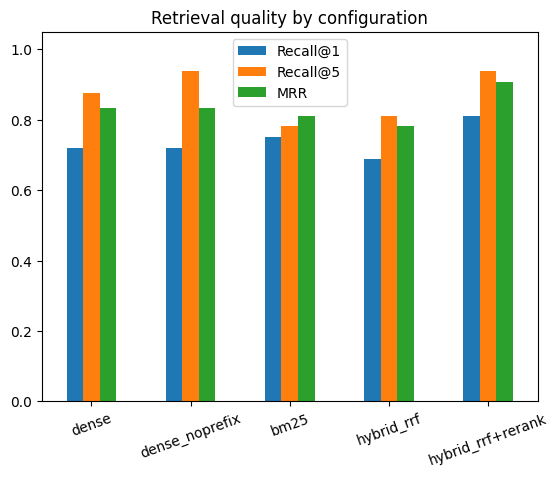

In [33]:
summary = pd.DataFrame(RESULTS).T
summary.loc["end-to-end", "answer_acc"] = round(ev.correct.mean(), 3)
summary.loc["end-to-end", "faithful"] = round((ev[ev.faithful.notna()].faithful == True).mean(), 3)
print("Backend:", BACKEND, HF_MODEL if BACKEND == "hf" else ANTHROPIC_MODEL)
display(summary)
summary[["Recall@1", "Recall@5", "MRR"]].dropna().plot.bar(rot=20, title="Retrieval quality by configuration")
plt.ylim(0, 1.05); plt.show()

### Report (write here)

1. **Best configuration** and by how much it beats dense-only on Recall@1 and MRR:
2. **One failure you could not fix** today, and the technique from the lecture you would try next (query rewriting, contextual retrieval, GraphRAG, agentic loop…):
3. **Context engineering:** one change from Part 1 you would apply to a real chatbot, and why:

Best configuration and by how much it beats dense-only on Recall@1 and MRR:

hybrid_rrf+rerank is the best configuration.

Recall@1: Reaches 0.812, beating dense (0.719) by +0.093 (+9.3 percentage points, placing the correct document first in ~1.5 more questions).
MRR: Reaches 0.906, beating dense (0.833) by +0.073 (and beating hybrid_rrf by +0.125).
It also matches the highest Recall@5 (0.938), demonstrating that the two-stage pipeline (hybrid retrieval followed by cross-encoder reranking) effectively pushes the true relevant chunk to the top.
One failure you could not fix today, and the technique from the lecture you would try next (query rewriting, contextual retrieval, GraphRAG, agentic loop…):

Unresolved failure: Question [6] ("Quantas vezes posso tentar subir a nota de uma cadeira?"), which targets Artigo 6.º (regped-art-6). It failed in retrieval misses across methods and in the final evaluation (correct = False). The failure stems from vocabulary mismatch: the student query uses informal idioms ("subir a nota", "cadeira"), whereas the academic regulation uses strict legal terms ("melhoria de classificação", "unidade curricular").

Technique to try next: Query Rewriting / HyDE (Hypothetical Document Embeddings). Having an LLM rewrite the user prompt into formal academic terminology or generate a hypothetical regulation snippet prior to retrieval bridges the lexical and semantic gap between student slang and official administrative text.

Context engineering: one change from Part 1 you would apply to a real chatbot, and why:

Dynamic Tool Selection (select): In Part 1, the raw tool definitions consumed 44.9% (3,066 tokens) of the entire prompt window, while the actual question took only 0.2%. In a production chatbot with dozens of APIs, injecting full JSON schemas on every turn wastes budget, raises latency, and distracts the LLM. Dynamically selecting only the 2–3 candidate tools relevant to the detected intent (or routing via a small triage classifier) drastically cuts token costs and reduces hallucinations.

## ★ Bonus (at home or for fast teams)

**B1 · Query rewriting for follow-ups.** `"E posso pagar tudo de uma vez?"` retrieves nothing useful on its own. Rewrite it into a standalone query using the conversation history, then retrieve.

In [34]:
def rewrite_query(history: list, follow_up: str) -> str:
  history_str = "\n".join(history)

  prompt = f"""Com base no histórico da conversa, reescreve a pergunta de seguimento como uma pergunta autónoma e completa em português europeu.
A pergunta reescrita deve ser compreensível sem o histórico.
NÃO respondas à pergunta. Devolve APENAS a pergunta reescrita, sem aspas, explicações ou texto adicional.

Histórico:
{history_str}

Pergunta de seguimento: {follow_up}

Pergunta autónoma:"""

  # Chamar o llm com poucas tokens para devolver apenas a frase da pergunta
  rewritten = llm(
      prompt,
      system=(
          "És um assistente que reescreve perguntas de seguimento para serem"
          " autónomas."
      ),
      max_tokens=60,
  )

  # Limpar eventuais aspas ou prefixos extra caso o modelo gere
  rewritten = re.sub(
      r'^(Pergunta autónoma:\s*|["\']|Pergunta:\s*)', "", rewritten.strip()
  )
  return rewritten.strip('"').strip("'").strip()


hist = [
    "Utilizador: Quanto custa a propina anual em 2026/2027?",
    "Assistente: A propina anual é de 710 euros [propinas-2026].",
]
fu = "E posso pagar tudo de uma vez?"
rq = rewrite_query(hist, fu)
print("raw      :", hybrid_rerank(fu, k=3))
print("rewritten:", rq, "->", hybrid_rerank(rq, k=3))


raw      : ['regped-art-6', 'reembolso-2023', 'reembolso-2026']
rewritten: Quanto tempo leva para receber a propina anual? -> ['reembolso-2026', 'propinas-2026', 'reembolso-2023']


**B2 · HyDE.** Generate a hypothetical answer, embed it and search with it. Evaluate as `"hyde"`. Does it help on the paraphrase questions (compare `MISSES["hyde"]` with `MISSES["dense"]`)? What does it cost?

In the original method the hypothetical answer is embedded **as a document**, so with E5 it takes the `passage: ` prefix.

In [35]:
def hyde_search(query: str, k: int = 10) -> list:
  # 1. Gerar um documento hipotético (falso parágrafo que responde à query no estilo de regulamento)
  prompt = f"""Escreve um parágrafo curto, no estilo formal de regulamento universitário português, que responda à seguinte questão:
"{query}"
Não incluas introduções. Escreve diretamente o texto regulamentar."""

  hypo = llm(
      prompt,
      system=(
          "És um redator de regulamentos e documentação académica universitária."
      ),
      max_tokens=80,
  )

  # 2. Gerar o embedding do parágrafo hipotético no espaço de documentos ("passage: ")
  hypo_emb = emb_model.encode("passage: " + hypo, normalize_embeddings=True)

  # 3. Calcular a similaridade contra P_EMB e devolver os ids dos k melhores chunks
  scores = P_EMB @ hypo_emb
  best_indices = np.argsort(scores)[::-1][:k]

  return [CHUNKS[i]["id"] for i in best_indices]


print(evaluate(hyde_search, "hyde"))
print("dense misses:", MISSES["dense"])
print("hyde misses :", MISSES["hyde"])


{'Recall@1': np.float64(0.594), 'Recall@5': np.float64(0.969), 'MRR': np.float64(0.802), 'ms/query': 3311.279}
dense misses: ['Quantas vezes posso tentar subir a nota de uma cadeira?', 'Qual é a nota mínima para passar a uma cadeira?']
hyde misses : ['Quem tem direito a época especial de exames?']


**B3 · A minimal agentic loop.** If the judge says the answer is unfaithful, or the model abstains, rewrite the query and retrieve again (at most 2 attempts). Log every step. Where could this loop go wrong in production?

In [36]:
def agentic_answer(question: str, max_steps: int = 2) -> dict:
  q = question
  log = []

  for step in range(max_steps):
    # 1. Obter resposta do RAG e avaliar com o juiz
    a = rag_answer(q)
    verdict = judge(a)
    is_faithful = verdict.get("faithful")

    # 2. Registar o passo
    log.append({
        "step": step,
        "query": q,
        "answer": a["answer"],
        "faithful": is_faithful,
    })

    # 3. Parar se for fiel e não for uma abstenção
    if is_faithful and not a["abstained"]:
      break

    # 4. Caso contrário, se ainda houver passos, reformular a pergunta
    if step < max_steps - 1:
      prompt = f"""A pesquisa com a pergunta "{q}" não produziu uma resposta totalmente suportada nos regulamentos para a pergunta original: "{question}".
Reformula esta pergunta de pesquisa usando outras palavras e sinónimos mais formais em português europeu (por exemplo, vocabulário administrativo ou regulamentar), mantendo o sentido original para não haver desvio.
Devolve APENAS a nova pergunta de pesquisa, sem explicações, aspas ou texto adicional."""

      new_q = llm(
          prompt,
          system=(
              "És um assistente encarregado de reformular perguntas de pesquisa."
          ),
          max_tokens=60,
      )

      # Limpar aspas e espaços
      new_q = re.sub(r'^(Nova pergunta:\s*|Pergunta:\s*)', "", new_q.strip())
      q = new_q.strip('"').strip("'").strip()

  return {"final": log[-1]["answer"], "log": log}


res = agentic_answer(
    "Quantas vezes posso tentar subir a nota de uma cadeira?"
)
display(pd.DataFrame(res["log"])[["step", "query", "faithful"]])
for s in res["log"]:
  print(f"\n[step {s['step']}] {s['query']}\n    {s['answer']}")


,step,query,faithful
0,0,Quantas vezes posso tentar subir a nota de uma...,False
1,1,Quantos esforços é permitido realizar para aum...,False



[step 0] Quantas vezes posso tentar subir a nota de uma cadeira?
    De acordo com o Regulamento Pedagógico, Artigo 4.º, existe a possibilidade de um aluno reprovado ou ausente na época normal tentar subir a nota na época de recurso, mediante inscrição prévia no portal académico.

[step 1] Quantos esforços é permitido realizar para aumentar a pontuação na avaliação de uma cadeira?
    De acordo com o artigo 6.º do Regulamento Pedagógico, o estudante pode requerer uma única melhoria de classificação em cada unidade curricular, na época de recurso do ano letivo seguinte ao da aprovação.
